# 6. Semi-infinite solids and phase change

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 4 and 5

When heat has not had time to reach the far side of a body, the body might as well be
infinitely thick. This *semi-infinite solid* is the right model for the ground, for skin
touching a cold object, and for the first moments of any sudden heating or cooling. This
chapter uses it for three questions from an Astana winter. Why does a steel railing at
−30 °C feel so much colder than a wooden bench at the same temperature? How deep into the
ground do the seasons reach, and when is the ground coldest? And how deep does the frost
go under a road that is cleared of snow, where the water in the soil must freeze before
the cold can pass?

The last question is a *Stefan problem*: the boundary between frozen and unfrozen soil
moves, and latent heat is released there. Neumann's exact solution answers it, and an
enthalpy-method finite-volume solver checks it.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import reference, transient
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import reference, transient
from engtransport.plotting import panel_label, use_style

use_style()
DAY, YEAR = 86400.0, 365.25 * 86400.0

## 6.1 The semi-infinite solid

A solid that fills $x > 0$ is at $T_i$ until, at $t = 0$, its surface is brought to $T_s$.
There is no length in this problem except $\sqrt{\alpha t}$, so the temperature can depend
on $x$ and $t$ only through $\eta = x/2\sqrt{\alpha t}$. Substituting into
$\partial T/\partial t = \alpha\,\partial^2 T/\partial x^2$ turns it into an ordinary
equation, $T'' + 2\eta T' = 0$, whose solution is the error function:

$$
\frac{T - T_s}{T_i - T_s} = \mathrm{erf}\,\frac{x}{2\sqrt{\alpha t}} .
\tag{6.1}
$$

Since $\mathrm{erf}\,2 = 0.995$, the disturbance has reached a depth of about $4\sqrt{\alpha
t}$. The heat flux into the surface follows from the slope there,

$$
q''_s = \frac{k\,(T_s - T_i)}{\sqrt{\pi \alpha t}} ,
\tag{6.2}
$$

large at first and falling as $t^{-1/2}$. Any body behaves as a semi-infinite solid while
$4\sqrt{\alpha t}$ is smaller than its thickness, which for the steel bar of Chapter 5
means the first few seconds of the quench.

## 6.2 Contact temperature: a steel railing at −30 °C

When two semi-infinite bodies at $T_1$ and $T_2$ are pressed together, each sees its
surface jump to a common temperature $T_c$ and stay there. By Eq. (6.2), the heat leaving
one body equals the heat entering the other only if
$\sqrt{k_1\rho_1c_1}\,(T_1 - T_c) = \sqrt{k_2\rho_2c_2}\,(T_c - T_2)$, so

$$
T_c = \frac{e_1T_1 + e_2T_2}{e_1 + e_2}, \qquad e = \sqrt{k\rho c} .
\tag{6.3}
$$

The *thermal effusivity* $e$ decides who wins. A hand (skin at 34 °C, $k = 0.37$ W/(m K),
$\rho c = 3.5$ MJ/(m³ K)) touches objects at −30 °C:

In [2]:
skin = dict(k=0.37, rho_c=1000 * 3500.0, T=34.0)
materials = {"steel": (45.0, 7850 * 470.0), "aluminium": (200.0, 2700 * 900.0), "ice": (2.2, 917 * 2100.0),
             "wood": (0.12, 500 * 2300.0), "snow": (0.2, 300 * 2100.0)}
T_cold = -30.0
contact = {}
print(f"skin: e = {math.sqrt(skin['k'] * skin['rho_c']):.0f} W s^0.5/(m2 K)")
for name, (k, rc) in materials.items():
    contact[name] = transient.contact_temperature(skin["k"], skin["rho_c"], skin["T"], k, rc, T_cold)
    print(f"{name:9s}: e = {math.sqrt(k * rc):6.0f}, skin surface at {contact[name]:6.1f} C")

skin: e = 1138 W s^0.5/(m2 K)
steel    : e =  12885, skin surface at  -24.8 C
aluminium: e =  22045, skin surface at  -26.9 C
ice      : e =   2058, skin surface at   -7.2 C
wood     : e =    371, skin surface at   18.2 C
snow     : e =    355, skin surface at   18.8 C


Steel and aluminium, with effusivities ten to twenty times that of skin, pull the skin
surface to −25 °C and −27 °C at the instant of contact. Wood and snow, with effusivities a
third of the skin's, leave it at 18–19 °C: a frozen wooden bench feels cool, a frozen
steel railing burns. Ice is in between, at −7 °C. Moist skin on steel at −25 °C freezes to
it within moments, which is why children are told never to lick a metal railing in
winter. The sensation of "cold" is the heat flux, and Eq. (6.3) says it is the effusivity,
not the temperature, that sets it.

## 6.3 The seasons in the ground

The surface of the ground follows the seasons. Take its temperature as
$T_m + A\cos\omega t$, with $\omega = 2\pi$/year. Once the start has been forgotten, the
temperature below is a damped wave travelling downwards:

$$
T = T_m + A\,e^{-x/d}\cos\left(\omega t - \frac{x}{d}\right), \qquad
d = \sqrt{\frac{2\alpha}{\omega}} .
\tag{6.4}
$$

The amplitude falls by a factor $e$ for each *damping depth* $d$, and the wave arrives later
by $1/\omega$ = 58 days per $d$. For Astana, with a mean of about 3 °C and January about
−14 °C, take $T_m = 3$ °C and $A = 18$ K at the surface. For moist soil,
$\alpha = 6.6 \times 10^{-7}$ m²/s:

In [3]:
rho_dry, w = 1600.0, 0.15                         # dry density (kg/m3), water per kg of dry soil
k_u, k_f = 1.5, 2.0                               # unfrozen and frozen soil (W/(m K))
C_u = rho_dry * (800.0 + w * 4190.0)              # volumetric heat capacities (J/(m3 K))
C_f = rho_dry * (800.0 + w * 2100.0)
L_v = rho_dry * w * 334e3                         # latent heat of the soil water (J/m3)
alpha_u = k_u / C_u
T_m, A_season = 3.0, 18.0
omega = 2 * math.pi / YEAR
d_damp = math.sqrt(2 * alpha_u / omega)
print(f"alpha = {alpha_u:.2e} m2/s, damping depth d = {d_damp:.2f} m, lag {1 / omega / DAY:.0f} days per d")
for x in (1.0, 2.0, 4.0, 8.0):
    print(f"x = {x:3.0f} m: swing +-{A_season * math.exp(-x / d_damp):5.2f} K, coldest {x / d_damp / omega / DAY:4.0f} days"
          f" after the surface, lowest temperature {T_m - A_season * math.exp(-x / d_damp):5.1f} C")
print(f"latent heat of the soil water {L_v / 1e6:.0f} MJ/m3 = sensible heat of {L_v / C_u:.0f} K of unfrozen soil")

alpha = 6.56e-07 m2/s, damping depth d = 2.57 m, lag 58 days per d
x =   1 m: swing +-12.19 K, coldest   23 days after the surface, lowest temperature  -9.2 C
x =   2 m: swing +- 8.26 K, coldest   45 days after the surface, lowest temperature  -5.3 C
x =   4 m: swing +- 3.79 K, coldest   91 days after the surface, lowest temperature  -0.8 C
x =   8 m: swing +- 0.80 K, coldest  181 days after the surface, lowest temperature   2.2 C
latent heat of the soil water 80 MJ/m3 = sensible heat of 35 K of unfrozen soil


At 2 m the swing is only ±8 K and arrives 45 days late, so the ground there is coldest
in early March, not in January. By 8 m the year is gone: the temperature stays within 0.8 K
of the annual mean. This is why a ground-source heat pump draws from a nearly constant
temperature, and why a cellar is warm in winter and cool in summer.

Equation (6.4) without latent heat says that ground below 0 °C reaches 4.6 m. That is far
too deep, because it ignores the water in the soil, which must give up its latent heat
before it freezes. With 15 % water by mass, that heat is 80 MJ/m³, as much as the soil
releases in cooling through 35 K. The next section takes it into account.

## 6.4 Frost under a road

A road cleared of snow has no blanket against the cold. Let its surface be held at the
average winter temperature $T_s = -10$ °C for a freezing season of 176 days, starting from
ground at $T_i = 5$ °C. Behind the freezing front $X(t)$ the soil is frozen; ahead of it, it
is not; and at the front, at $T_f = 0$ °C, the heat conducted away through the frozen
soil exceeds that conducted in from the warm soil by the latent heat released:

$$
k_f \left.\frac{\partial T}{\partial x}\right|_{X^-} - k_u \left.\frac{\partial T}{\partial x}\right|_{X^+}
= L_v\,\frac{dX}{dt} .
\tag{6.5}
$$

If the latent heat dominates, the frozen layer is nearly a steady conductor with
$T_f - T_s$ across it, and Eq. (6.5) gives Stefan's formula:

$$
X \approx \sqrt{\frac{2k_f\,(T_f - T_s)\,t}{L_v}} .
\tag{6.6}
$$

Neumann found the exact solution. Both regions have error-function profiles like
Eq. (6.1), and the front moves as $X = 2\lambda\sqrt{\alpha_f t}$, with $\lambda$ the root of
the Stefan condition (6.5):

$$
\frac{k_f (T_f - T_s)\,e^{-\lambda^2}}{\sqrt{\pi\alpha_f}\,\mathrm{erf}\lambda}
- \frac{k_u (T_i - T_f)\,e^{-\lambda^2\alpha_f/\alpha_u}}
       {\sqrt{\pi\alpha_u}\,\mathrm{erfc}\left(\lambda\sqrt{\alpha_f/\alpha_u}\right)}
= L_v \lambda \sqrt{\alpha_f} .
\tag{6.7}
$$

`transient.neumann_freezing` solves it:

In [4]:
T_s, T_freeze, T_i = -10.0, 0.0, 5.0
season = 176 * DAY
frost = transient.neumann_freezing(k_f, C_f, k_u, C_u, L_v, T_s, T_freeze, T_i)
X_neumann = float(frost["front"](season))
X_stefan = math.sqrt(2 * k_f * (T_freeze - T_s) * season / L_v)
print(f"lambda = {frost['lam']:.4f}; after 176 days: Neumann {X_neumann:.2f} m, Stefan's formula {X_stefan:.2f} m")
print(f"Stefan number C_f (T_f - T_s)/L_v = {C_f * (T_freeze - T_s) / L_v:.3f}")
for T_surf in (-5.0, -15.0):
    sol = transient.neumann_freezing(k_f, C_f, k_u, C_u, L_v, T_surf, T_freeze, T_i)
    print(f"surface at {T_surf:.0f} C: {float(sol['front'](season)):.2f} m")

lambda = 0.2831; after 176 days: Neumann 2.34 m, Stefan's formula 2.75 m
Stefan number C_f (T_f - T_s)/L_v = 0.223
surface at -5 C: 1.62 m
surface at -15 C: 2.87 m


The frost reaches 2.34 m after 176 days. Field measurements under the Astana–Burabay
highway report 2.45 m after a freezing season of 176 days, so this simple model, with
assumed soil properties and a constant surface temperature, is close. Stefan's formula
gives 2.75 m, 18 % too deep: it ignores the heat still stored in the warm soil below the
front, which flows up and slows the freezing. Because $X \propto \sqrt{t}$, the front moves
fast at first and slowly later: half the final depth is reached in a quarter of the
season. The depth grows only as the square root of the surface cold: from −5 to −15 °C it
goes from 1.6 to 2.9 m.

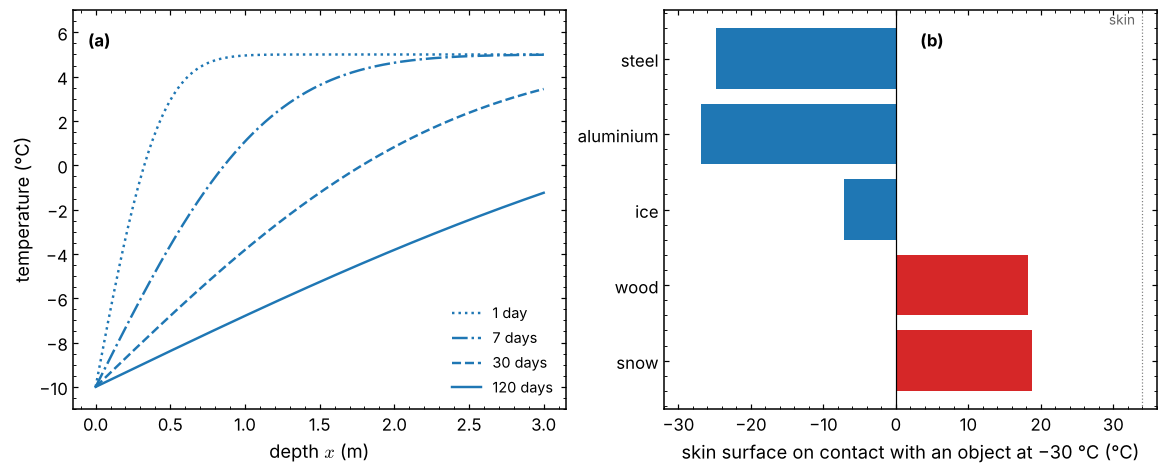

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
x_plot = np.linspace(0, 3.0, 300)
for days, style in ((1, ":"), (7, "-."), (30, "--"), (120, "-")):
    T_prof = T_s + (T_i - T_s) * transient.erf_array(x_plot / (2 * math.sqrt(alpha_u * days * DAY)))
    ax1.plot(x_plot, T_prof, "C0" + style, label=f"{days} day" + ("s" if days > 1 else ""))
ax1.set_xlabel("depth $x$ (m)")
ax1.set_ylabel("temperature (°C)")
ax1.set_ylim(-11, 7)
ax1.legend(loc="lower right")
panel_label(ax1, "(a)")

names = list(contact)
ax2.barh(names, [contact[n] for n in names], color=["C0" if contact[n] < 0 else "C3" for n in names])
ax2.axvline(0, color="k", lw=0.8)
ax2.axvline(skin["T"], color="0.5", lw=0.8, ls=":")
ax2.text(skin["T"] - 1, -0.45, "skin", ha="right", fontsize=9, color="0.4")
ax2.set_xlabel("skin surface on contact with an object at −30 °C (°C)")
ax2.set_xlim(-32, 36)
ax2.invert_yaxis()
panel_label(ax2, "(b)", x=0.52)
plt.show()

**Figure 6.1.** (a) Temperature in ground at 5 °C whose surface is held at −10 °C from
time zero, without latent heat, Eq. (6.1), after 1, 7, 30 and 120 days. (b) Temperature of
the skin surface at the instant a hand at 34 °C touches objects at −30 °C, Eq. (6.3).

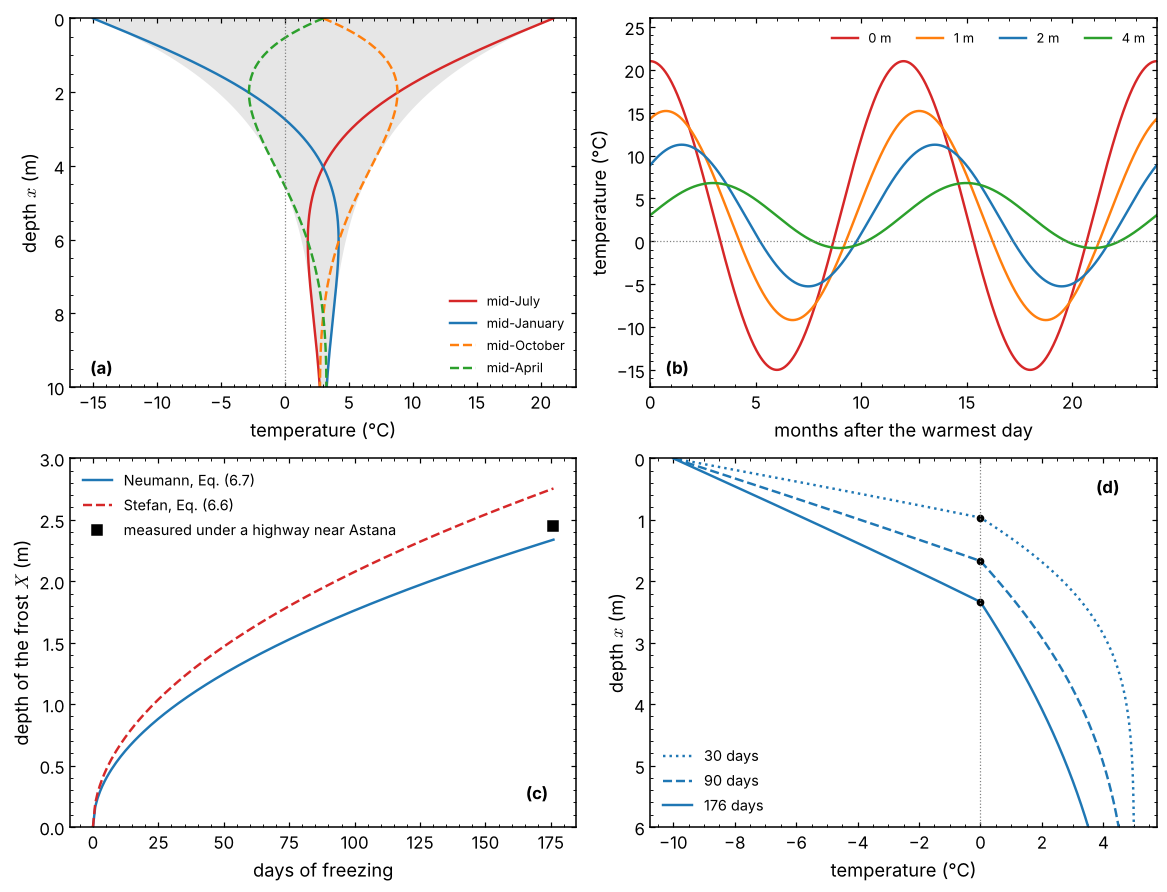

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
xs = np.linspace(0, 10, 300)
ax.fill_betweenx(xs, T_m - A_season * np.exp(-xs / d_damp), T_m + A_season * np.exp(-xs / d_damp), color="0.9", lw=0)
for phase, name, style in ((0.0, "mid-July", "C3-"), (0.5, "mid-January", "C0-"), (0.25, "mid-October", "C1--"),
                           (0.75, "mid-April", "C2--")):
    ax.plot(transient.periodic_surface(xs, phase * YEAR, alpha_u, T_m, A_season, YEAR), xs, style, label=name)
ax.axvline(0, color="0.5", lw=0.8, ls=":")
ax.set_ylim(10, 0)
ax.set_xlabel("temperature (°C)")
ax.set_ylabel("depth $x$ (m)")
ax.legend(loc="lower right", fontsize=8.5)
panel_label(ax, "(a)", x=0.04, y=0.08)

ax = axes[0, 1]
tt = np.linspace(0, 2 * YEAR, 731)
for x, style in ((0.0, "C3-"), (1.0, "C1-"), (2.0, "C0-"), (4.0, "C2-")):
    ax.plot(tt / DAY / 30.44, transient.periodic_surface(x, tt, alpha_u, T_m, A_season, YEAR), style,
            label=f"{x:g} m")
ax.axhline(0, color="0.5", lw=0.8, ls=":")
ax.set_xlabel("months after the warmest day")
ax.set_ylabel("temperature (°C)")
ax.set_xlim(0, 24)
ax.set_ylim(-17, 26)
ax.legend(loc="upper right", ncol=4, fontsize=8.5)
panel_label(ax, "(b)", y=0.08)

ax = axes[1, 0]
days = np.linspace(0, 176, 200)
ax.plot(days, frost["front"](days * DAY), "C0", label="Neumann, Eq. (6.7)")
ax.plot(days, np.sqrt(2 * k_f * (T_freeze - T_s) * days * DAY / L_v), "C3--", label="Stefan, Eq. (6.6)")
ax.plot([176], [2.45], "ks", ms=6, label="measured under a highway near Astana")
ax.set_xlabel("days of freezing")
ax.set_ylabel("depth of the frost $X$ (m)")
ax.set_ylim(0, 3)
ax.legend(loc="upper left")
panel_label(ax, "(c)", x=0.9, y=0.12)

ax = axes[1, 1]
xx = np.linspace(0, 6, 400)
for dd, style in ((30, ":"), (90, "--"), (176, "-")):
    ax.plot(frost["T"](xx, dd * DAY), xx, "C0" + style, label=f"{dd} days")
    ax.plot([T_freeze], [frost["front"](dd * DAY)], "ko", ms=4)
ax.axvline(T_freeze, color="0.5", lw=0.8, ls=":")
ax.set_ylim(6, 0)
ax.set_xlabel("temperature (°C)")
ax.set_ylabel("depth $x$ (m)")
ax.legend(loc="lower left")
panel_label(ax, "(d)", x=0.88)
plt.show()

**Figure 6.2.** (a) The seasonal wave in the ground, Eq. (6.4), with the surface at
3 ± 18 °C: temperature profiles at four times of the year inside the envelope of the
swing. (b) Temperature against time at the surface and at depths of 1, 2 and 4 m. (c) Depth
of the frost under a road cleared of snow, with its surface at −10 °C, from Neumann's
solution and Stefan's formula, and the depth measured after a freezing season of 176 days.
(d) Temperature in the freezing ground after 30, 90 and 176 days; the dots mark the front.

## 6.5 Checks

`reference.enthalpy_1d_fv` follows each cell's enthalpy rather than its temperature. A cell
that is freezing stays at 0 °C while it gives up its latent heat, and only then cools
further, so the front need not be tracked: it is wherever cells are partly frozen. The
solver also accepts layers of different materials and a surface temperature that changes
with time, and it keeps an account of the energy.

*Freezing.* The frost depth and the temperature profile against Neumann's solution, on
grids of 40, 20 and 10 mm.

*Contact.* Skin (10 mm) against steel (50 mm), with no latent heat: the interface
temperature against Eq. (6.3).

*The seasons.* Five years of a cosine surface temperature on soil with no latent heat; the
swing in the last year against Eq. (6.4).

In [7]:
grids = np.array([0.04, 0.02, 0.01])
front_err, runs = [], {}
for dx in grids:
    faces = np.arange(0.0, 10.0 + dx / 2, dx)
    out = reference.enthalpy_1d_fv(faces, k_f, C_f, k_u, C_u, L_v, T_freeze, T_i, season,
                                   left=("temperature", T_s), right=("temperature", T_i),
                                   t_save=[30 * DAY, 90 * DAY, season])
    runs[dx] = out
    front_err.append(np.abs(out["front"] - frost["front"](out["t"])))
front_err = np.array(front_err)
for dx, e, out in zip(grids, front_err, runs.values()):
    print(f"dx = {1e3 * dx:2.0f} mm: front error {1e3 * e[-1]:.1f} mm at 176 days, energy balance {out['balance']:.0e}")
order = np.polyfit(np.log(grids), np.log(front_err[:, 0]), 1)[0]
print(f"order of convergence of the front at 30 days: {order:.2f}")
fine = runs[0.01]
print(f"largest temperature difference at 176 days (10 mm grid): {np.max(np.abs(fine['T'][-1] - frost['T'](fine['x'], season))):.3f} K")

dxc = 1e-4
faces_c = np.arange(0.0, 0.06 + dxc / 2, dxc)                     # 10 mm of skin, 50 mm of steel
xc = 0.5 * (faces_c[1:] + faces_c[:-1])
is_skin = xc < 0.01
k_c = np.where(is_skin, skin["k"], 45.0)
C_c = np.where(is_skin, skin["rho_c"], 7850 * 470.0)
t_c = np.linspace(0.01, 5.0, 200)
touch = reference.enthalpy_1d_fv(faces_c, k_c, C_c, k_c, C_c, 0.0, -1000.0, np.where(is_skin, skin["T"], T_cold), 5.0,
                                 t_save=t_c)
j = int(np.argmax(~is_skin))
G1, G2 = skin["k"] / (dxc / 2), 45.0 / (dxc / 2)
T_interface = (G1 * touch["T"][:, j - 1] + G2 * touch["T"][:, j]) / (G1 + G2)
print(f"contact: interface {T_interface[-1]:.3f} C after 5 s, Eq. (6.3) {contact['steel']:.3f} C")

dxs = 0.1
faces_s = np.arange(0.0, 15.0 + dxs / 2, dxs)
t_years = np.linspace(4 * YEAR, 5 * YEAR, 147)
wave = reference.enthalpy_1d_fv(faces_s, k_u, C_u, k_u, C_u, 0.0, -1000.0, T_m, 5 * YEAR,
                                left=("temperature", lambda t: T_m + A_season * math.cos(omega * t)),
                                t_save=t_years)
swing_fv = 0.5 * (wave["T"].max(axis=0) - wave["T"].min(axis=0))
swing_exact = A_season * np.exp(-wave["x"] / d_damp)
sel = wave["x"] < 8
print(f"seasons: largest error in the swing above 8 m {np.max(np.abs(swing_fv - swing_exact)[sel]):.3f} K")

dx = 40 mm: front error 4.0 mm at 176 days, energy balance -4e-15
dx = 20 mm: front error 1.6 mm at 176 days, energy balance -2e-14
dx = 10 mm: front error 0.8 mm at 176 days, energy balance -5e-13
order of convergence of the front at 30 days: 1.01
largest temperature difference at 176 days (10 mm grid): 0.209 K


contact: interface -24.806 C after 5 s, Eq. (6.3) -24.806 C


seasons: largest error in the swing above 8 m 0.003 K


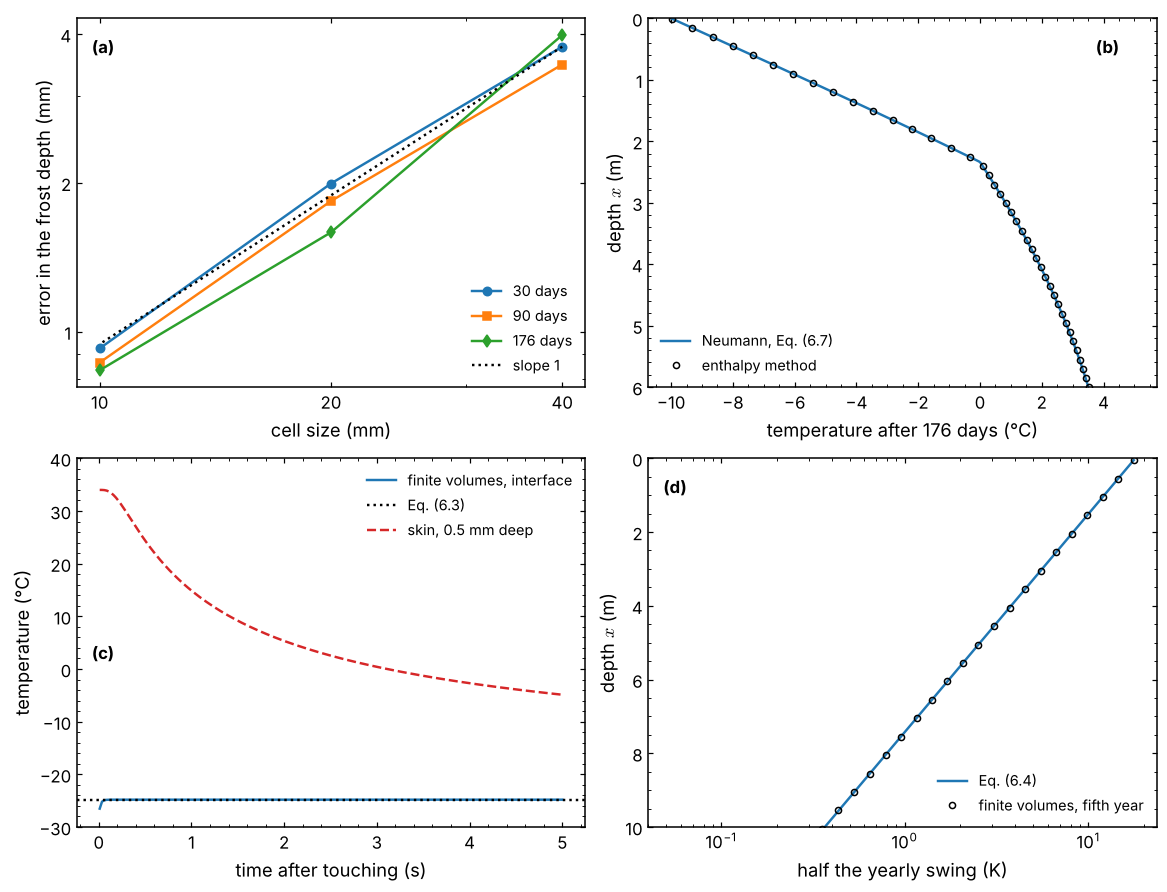

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
for i, (days_s, marker) in enumerate(((30, "o"), (90, "s"), (176, "d"))):
    ax.loglog(grids * 1e3, front_err[:, i] * 1e3, marker + "-", label=f"{days_s} days")
ax.loglog(grids * 1e3, front_err[0, 0] * 1e3 * grids / grids[0], "k:", label="slope 1")
ax.set_xticks([10, 20, 40])
ax.set_yticks([1, 2, 4])
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(plt.ScalarFormatter())
    axis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("cell size (mm)")
ax.set_ylabel("error in the frost depth (mm)")
ax.legend(loc="lower right")
panel_label(ax, "(a)")

ax = axes[0, 1]
ax.plot(frost["T"](xx, season), xx, "C0", label="Neumann, Eq. (6.7)")
ax.plot(fine["T"][-1][::15], fine["x"][::15], "ko", ms=4, mfc="none", label="enthalpy method")
ax.set_ylim(6, 0)
ax.set_xlabel("temperature after 176 days (°C)")
ax.set_ylabel("depth $x$ (m)")
ax.legend(loc="lower left")
panel_label(ax, "(b)", x=0.88)

ax = axes[1, 0]
ax.plot(t_c, T_interface, "C0", label="finite volumes, interface")
ax.axhline(contact["steel"], color="k", ls=":", label="Eq. (6.3)")
ax.plot(t_c, touch["T"][:, j - 5], "C3--", label="skin, 0.5 mm deep")
ax.set_xlabel("time after touching (s)")
ax.set_ylabel("temperature (°C)")
ax.set_ylim(-30, 40)
ax.legend(loc="upper right")
panel_label(ax, "(c)", y=0.5)

ax = axes[1, 1]
ax.plot(swing_exact, wave["x"], "C0", label="Eq. (6.4)")
ax.plot(swing_fv[::5], wave["x"][::5], "ko", ms=4, mfc="none", label="finite volumes, fifth year")
ax.set_ylim(10, 0)
ax.set_xscale("log")
ax.set_xlabel("half the yearly swing (K)")
ax.set_ylabel("depth $x$ (m)")
ax.legend(loc="lower right")
panel_label(ax, "(d)")
plt.show()

**Figure 6.3.** Checks. (a) Error in the depth of the frost from the enthalpy method against
the cell size, after 30, 90 and 176 days; the dotted line has slope 1. (b) Temperature
after 176 days, Neumann's solution and the enthalpy method (10 mm cells). (c) Skin against
steel at −30 °C: the interface temperature from finite volumes, Eq. (6.3), and the
temperature 0.5 mm into the skin. (d) Half the yearly temperature swing against depth, from
Eq. (6.4) and from five years of finite volumes.

The enthalpy method converges on Neumann's front at first order, the usual rate for this
method, and is within 1 mm with 10 mm cells; the energy balance closes to rounding error.
The temperatures agree to 0.2 K, the largest differences being next to the front, where a
cell that is still freezing holds its temperature at 0 °C. The skin–steel interface settles at
the contact temperature (6.3) within milliseconds, while half a millimetre into the skin the
cold arrives only after a fraction of a second and then deepens steadily. After five years the computed seasonal swing matches Eq. (6.4) at
every depth.

## 6.6 What to trust

* *The soil.* Its conductivity, heat capacity and above all its water content vary from
  place to place and with the season; the latent heat is proportional to the water. Fine
  soils also keep some water unfrozen below 0 °C, so they freeze over a range of
  temperatures. The answer of Section 6.4 is good to perhaps ±20 %.
* *The surface.* A constant surface temperature is the crudest part of the model. Snow,
  even a thin layer, insulates the ground strongly (Exercise 2), which is why frost goes
  deepest under cleared roads and runways.
* *Frost heave.* Water drawn to the front forms ice lenses that lift the road; this is a
  mass-transfer effect that the model leaves out.
* *Contact.* Equation (6.3) is exact for the first moments of contact, while both bodies
  are effectively semi-infinite, and assumes perfect thermal contact. A glove or a layer
  of air changes the answer entirely.

## Summary

* A suddenly cooled or heated semi-infinite solid has the error-function profile (6.1);
  the disturbance reaches about $4\sqrt{\alpha t}$, and the surface flux falls as $t^{-1/2}$,
  Eq. (6.2).
* Two bodies in contact meet at the effusivity-weighted temperature (6.3); effusivity, not
  temperature, decides how cold something feels.
* A periodic surface temperature penetrates as a damped wave with damping depth
  $\sqrt{2\alpha/\omega}$, Eq. (6.4): about 2.6 m for the yearly cycle in moist soil.
* Freezing ground is a Stefan problem, Eq. (6.5). Stefan's formula (6.6) overestimates the
  frost depth; Neumann's solution (6.7) is exact for constant properties.

## Exercises

Sample solutions are in [`solutions/part1_conduction/06_solutions.ipynb`](../../solutions/part1_conduction/06_solutions.ipynb).

1. **How long until it hurts?** Skin feels pain when its surface falls below about 15 °C,
   and nerves 1 mm below the surface signal cold. A hand at 34 °C grips the steel railing
   of Section 6.2. Treating both as semi-infinite, find how long it takes for the skin
   1 mm deep to reach 15 °C. Repeat for the aluminium handle of a car door.
2. **Snow on the road.** If the road of Section 6.4 is left under 30 cm of snow,
   $k = 0.2$ W/(m K), with −10 °C at the top of the snow, the snow acts as a resistance in
   series with the frozen soil. Extend Stefan's argument to show that
   $X^2/2k_f + XR''_{\rm snow} = (T_f - T_s)\,t/L_v$, find the frost depth after 176 days, and
   check it with `reference.enthalpy_1d_fv` (snow as a layer without latent heat).
3. **The water main.** Water mains in cold climates are buried below the frost. Use the
   enthalpy method with the seasonal surface temperature of Section 6.3 (no snow) for two
   years, starting from 3 °C, to find the deepest the 0 °C isotherm reaches. Compare it with
   Eq. (6.4) without latent heat and with the Neumann estimate of Section 6.4.
4. **Stefan's formula.** Show that for soil that starts at the freezing temperature
   ($T_i = T_f$), Eq. (6.7) reduces to $\lambda e^{\lambda^2}\mathrm{erf}\lambda =
   \mathrm{Ste}/\sqrt{\pi}$, with $\mathrm{Ste} = C_f(T_f - T_s)/L_v$, and that Stefan's
   formula (6.6) is its limit for small Ste. How large may Ste be for Eq. (6.6) to be
   within 5 %?

## Suggested references

* H. S. Carslaw and J. C. Jaeger, *Conduction of Heat in Solids*, 2nd ed. (Oxford
  University Press, 1959).
* J. Stefan, "Über die Theorie der Eisbildung, insbesondere über die Eisbildung im
  Polarmeere", *Ann. Phys.* **278**, 269 (1891).
* V. R. Voller and M. Cross, "Accurate solutions of moving boundary problems using the
  enthalpy method", *Int. J. Heat Mass Transfer* **24**, 545 (1981).
* Frost penetration under the Astana–Burabay highway: ISSMGE Technical Committee 202,
  15th Asian Regional Conference, presentation TC202-10,
  [eng.hokudai.ac.jp/labo/geomech/ISSMGE TC202](https://www.eng.hokudai.ac.jp/labo/geomech/ISSMGE%20TC202/archive/15thARCTC202/TC202-10.pdf).

---

**Previous:** [5. Transient conduction](05_transient.ipynb) &nbsp;·&nbsp; **Next:** [7. Boundary layers and external flow](../part2_convection/07_boundary_layers.ipynb)